# E2：平均勾配を用いる手法のスナップショットと初期値のアブレーション（CIFAR-10）

`programs/analysis_e2.py` を呼び，E0（`ex002`）の6条件と E2（`ex007`）の新規条件を合わせて表と図を作る．

- `SHOW_CONDITIONS`：平均勾配の図に描く条件（`analysis_e2.AVERAGE_GRADIENT_IDS` の部分集合）を指定する．

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('programs'))
import analysis_e2 as a2
from IPython.display import Markdown, Image, display

SHOW_CONDITIONS = list(a2.AVERAGE_GRADIENT_IDS)  # 描く条件を選ぶ
a2.AVERAGE_GRADIENT_IDS[:] = SHOW_CONDITIONS

In [2]:
text = a2.write_summary()
display(Markdown(text))

/home/user/workspace/ASAI_SVRG_programs/programs_review/programs/analysis_e2.py:288: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(values, axis=0)
/home/user/workspace/ASAI_SVRG_programs/.venv_pytorch/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1997: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


# E2：平均勾配を用いる手法のスナップショットと初期値のアブレーション（CIFAR-10，集計結果）

値は5シードの平均 ± 標準誤差である．予算は $ \#\mathrm{grad}/N \le 90 $ の最後の評価点（平均勾配の手法は45エポック，全勾配の手法は29エポック）．精度の変化量は予算の後半における $ |a_s - a_{s-1}| $ の平均，近似誤差と ω/ω_min は予算の後半の中央値である．restart は `inner_start="snapshot"`，continue は `"last_iterate"` である．

最終点（NFG-final，SVRG-final）と SVRG-average (restart) は別のPCの結果（`ex007_e2_cifar10_snapshot_gradient_factorial`），その他は本PCの結果である．GPU の違いによる丸め誤差のため，同じ条件でも PC 間で値が少し異なる．48エポック目のテスト精度の PC 間の差は，SVRG・ASA-SVRG（restart）で0.003以下，学習が不安定な NFG-SVRG（restart）で0.05（シード間の標準誤差0.04と同程度）である．このため，異なる PC の条件の対応のある差は，PC 間の差より十分大きい場合のみ解釈する．

## アブレーションの表

| $ g_s $ | スナップショット | 初期値 | シード数 | 学習損失（予算） | テスト精度（予算） | 学習損失（48エポック） | テスト精度（48エポック） | 精度の変化量 | 近似誤差の中央値（後半） | ω/ω_min の中央値（後半） | 打ち切り |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 平均勾配 | ランダム点 | snapshot | 5 | 2.2109 ± 0.1325 | 0.3023 ± 0.0371 | 2.1586 ± 0.1528 | 0.3188 ± 0.0400 | 0.0297 ± 0.0056 | 1.819e+00 ± 7.3e-01 | — | 0 |
| 平均勾配 | ランダム点 | last_iterate | 5 | 2.4403 ± 0.0985 | 0.1600 ± 0.0451 | 2.4334 ± 0.1052 | 0.1640 ± 0.0470 | 0.0169 ± 0.0048 | 2.879e-03 ± 2.9e-03 | — | 0 |
| 平均勾配 | 最終点 | 最終点で同一 | 5 | 2.2502 ± 0.1232 | 0.2708 ± 0.0429 | 2.3465 ± 0.1163 | 0.2203 ± 0.0474 | 0.0261 ± 0.0063 | 2.011e+00 ± 1.9e+00 | 4.0272 ± 0.0166 | 0 |
| 平均勾配 | 平均点 | snapshot | 5 | 0.8851 ± 0.0026 | 0.7126 ± 0.0019 | 0.8448 ± 0.0026 | 0.7189 ± 0.0013 | 0.0047 ± 0.0001 | 8.691e-02 ± 2.9e-03 | — | 0 |
| 平均勾配 | 平均点 | last_iterate | 5 | 0.3894 ± 0.0022 | 0.7520 ± 0.0017 | 0.3423 ± 0.0015 | 0.7530 ± 0.0013 | 0.0023 ± 0.0000 | 1.115e-01 ± 3.4e-03 | — | 0 |
| 全勾配 | ランダム点 | snapshot | 5 | 1.1524 ± 0.0237 | 0.6463 ± 0.0069 | 0.8644 ± 0.0241 | 0.7102 ± 0.0042 | 0.0132 ± 0.0012 | （全勾配） | — | 0 |
| 全勾配 | ランダム点 | last_iterate | 5 | 0.7713 ± 0.0174 | 0.7213 ± 0.0055 | 0.3283 ± 0.0029 | 0.7535 ± 0.0010 | 0.0129 ± 0.0018 | （全勾配） | — | 0 |
| 全勾配 | 平均点 | last_iterate | 5 | 0.7223 ± 0.0024 | 0.7354 ± 0.0013 | 0.3253 ± 0.0019 | 0.7540 ± 0.0014 | 0.0061 ± 0.0001 | （全勾配） | 1.0000 ± 0.0000 | 0 |
| 全勾配 | 平均点 | snapshot | 5 | 1.1148 ± 0.0024 | 0.6619 ± 0.0008 | 0.8265 ± 0.0023 | 0.7217 ± 0.0013 | 0.0086 ± 0.0001 | （全勾配） | 1.0000 ± 0.0000 | 0 |
| 全勾配 | 最終点 | 最終点で同一 | 5 | 0.7680 ± 0.0105 | 0.7148 ± 0.0041 | 0.3473 ± 0.0153 | 0.7458 ± 0.0052 | 0.0143 ± 0.0011 | （全勾配） | 3.4441 ± 0.0100 | 0 |

## 最良の構成の選択（実験計画4.5節：平均勾配の5パターン，予算での学習損失）

| 順位 | 条件 | 学習損失（予算，平均 ± 標準誤差） | シード数 |
|---:|---|---:|---:|
| 1 | ASA-SVRG (continue) | 0.3894 ± 0.0022 | 5 |
| 2 | ASA-SVRG (restart) | 0.8851 ± 0.0026 | 5 |
| 3 | NFG-SVRG (restart) | 2.2109 ± 0.1325 | 5 |
| 4 | NFG-final | 2.2502 ± 0.1232 | 5 |
| 5 | NFG-SVRG (continue) | 2.4403 ± 0.0985 | 5 |

最良の構成：**ASA-SVRG (continue)**

## 対応のある差（同じシード）

| 比較 | A − B | 学習損失（予算） | テスト精度（予算） | 学習損失（48エポック） | テスト精度（48エポック） |
|---|---|---:|---:|---:|---:|
| 近似誤差の効果（平均点，continue） | ASA-SVRG (continue) − SVRG-average (continue) | -0.3329 ± 0.0012 | 0.0166 ± 0.0013 | 0.0170 ± 0.0007 | -0.0010 ± 0.0009 |
| 近似誤差の効果（ランダム点，continue） | NFG-SVRG (continue) − SVRG (continue) | 1.6690 ± 0.1085 | -0.5613 ± 0.0483 | 2.1051 ± 0.1079 | -0.5894 ± 0.0468 |
| 近似誤差の効果（ランダム点，restart） | NFG-SVRG (restart) − SVRG (restart) | 1.0586 ± 0.1299 | -0.3439 ± 0.0386 | 1.2941 ± 0.1454 | -0.3914 ± 0.0396 |
| 近似誤差の効果（最終点） | NFG-final − SVRG-final | 1.4822 ± 0.1174 | -0.4441 ± 0.0413 | 1.9992 ± 0.1051 | -0.5255 ± 0.0454 |
| 近似誤差の効果（平均点，restart） | ASA-SVRG (restart) − SVRG-average (restart) | -0.2298 ± 0.0014 | 0.0507 ± 0.0025 | 0.0183 ± 0.0005 | -0.0028 ± 0.0004 |
| スナップショットの効果（平均勾配，平均点 − 最終点） | ASA-SVRG (continue) − NFG-final | -1.8608 ± 0.1216 | 0.4812 ± 0.0433 | -2.0042 ± 0.1156 | 0.5327 ± 0.0481 |
| スナップショットの効果（平均勾配，平均点 − ランダム点，continue） | ASA-SVRG (continue) − NFG-SVRG (continue) | -2.0509 ± 0.1002 | 0.5920 ± 0.0445 | -2.0910 ± 0.1062 | 0.5890 ± 0.0471 |
| スナップショットの効果（全勾配，平均点 − ランダム点，continue） | SVRG-average (continue) − SVRG (continue) | -0.0490 ± 0.0157 | 0.0140 ± 0.0048 | -0.0029 ± 0.0025 | 0.0005 ± 0.0005 |

## 図

- `ex007_e2_cifar10_ablation/figures/e2_average_gradient_train_loss.png`
- `ex007_e2_cifar10_ablation/figures/e2_average_gradient_test_accuracy.png`
- `ex007_e2_cifar10_ablation/figures/e2_average_gradient_approx_error.png`
- `ex007_e2_cifar10_ablation/figures/e2_asa_vs_svrg_average_train_loss_grad.png`
- `ex007_e2_cifar10_ablation/figures/e2_asa_vs_svrg_average_train_loss_epoch.png`
- `ex007_e2_cifar10_ablation/figures/e2_asa_vs_svrg_average_test_accuracy_grad.png`
- `ex007_e2_cifar10_ablation/figures/e2_asa_vs_svrg_average_test_accuracy_epoch.png`
- `ex007_e2_cifar10_ablation/figures/e2_omega.png`


e2_asa_vs_svrg_average_test_accuracy_epoch.png


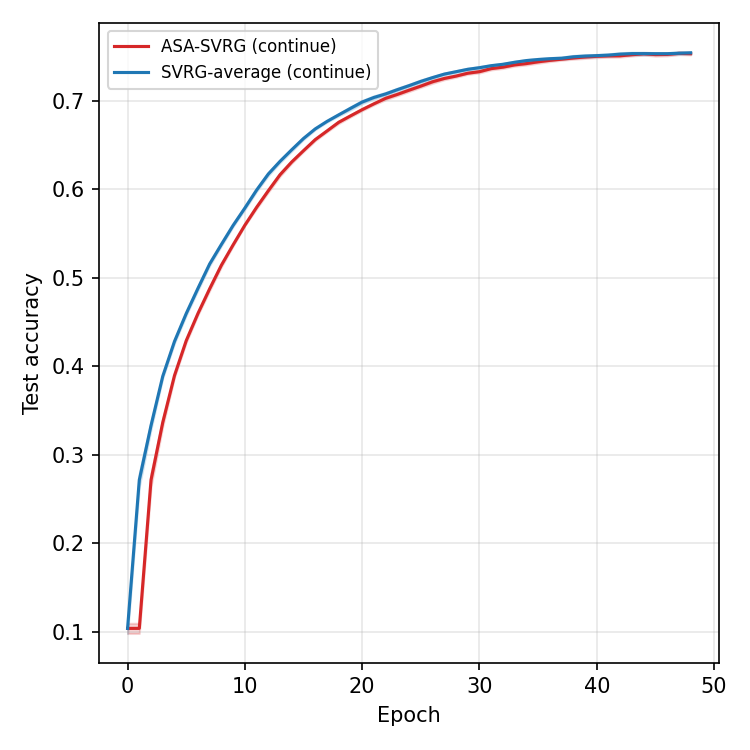

e2_asa_vs_svrg_average_test_accuracy_grad.png


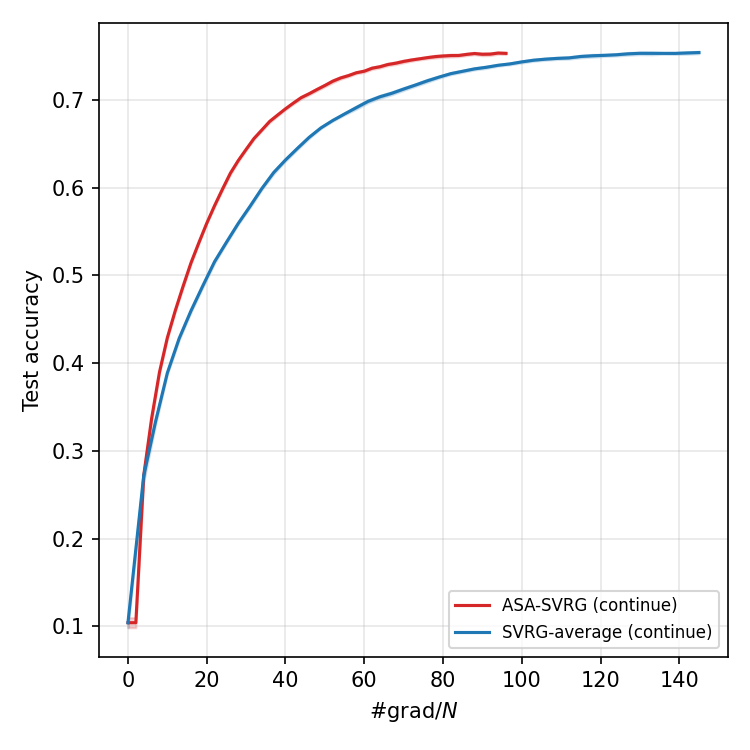

e2_asa_vs_svrg_average_train_loss_epoch.png


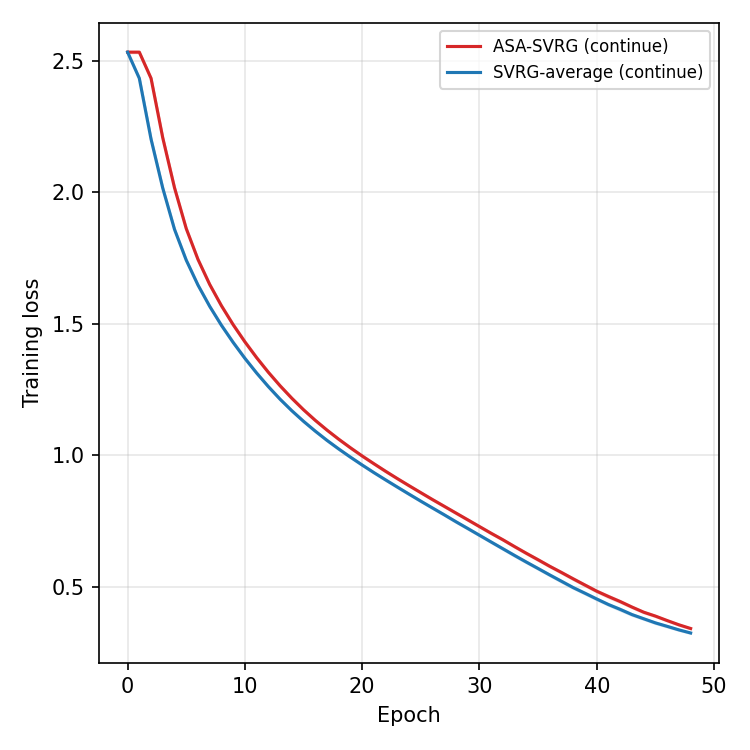

e2_asa_vs_svrg_average_train_loss_grad.png


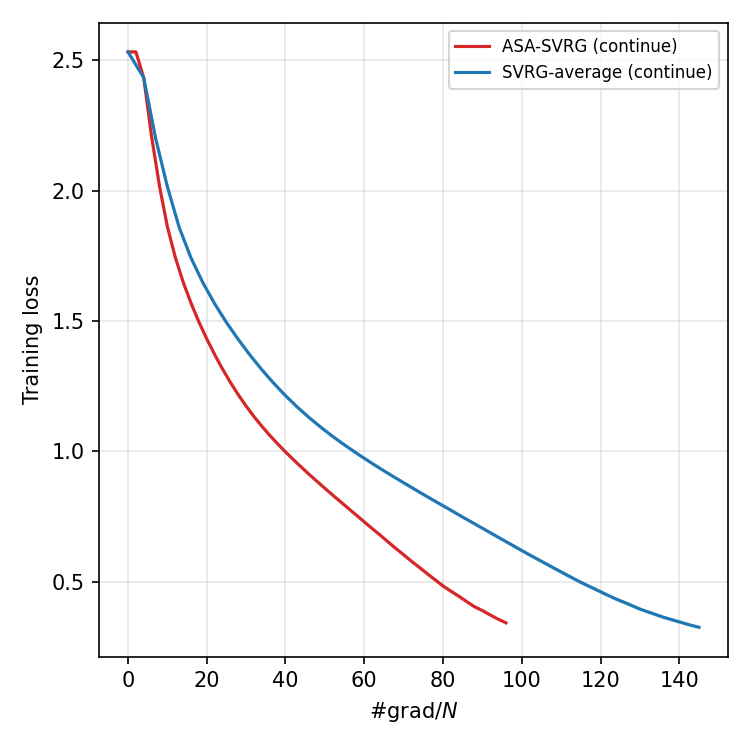

e2_average_gradient_approx_error.png


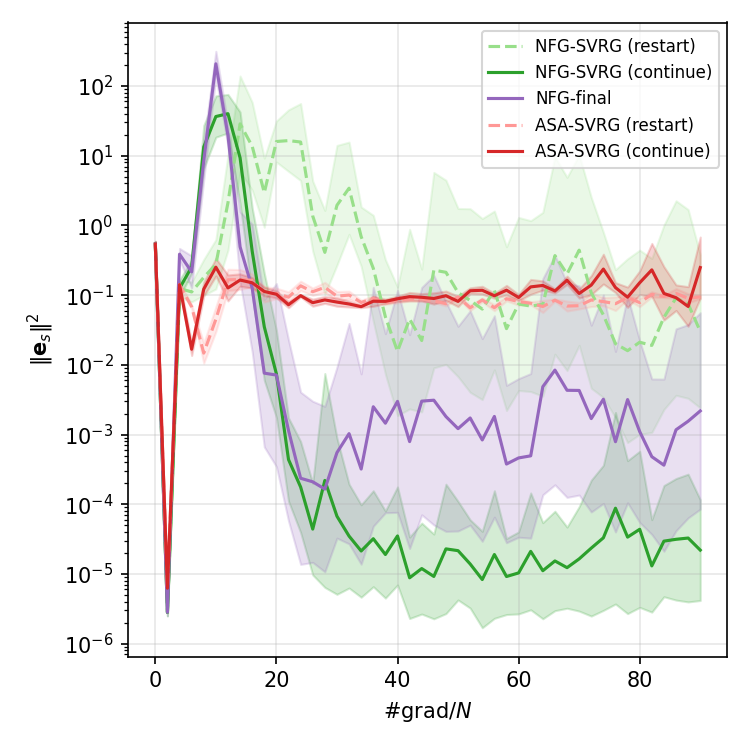

e2_average_gradient_test_accuracy.png


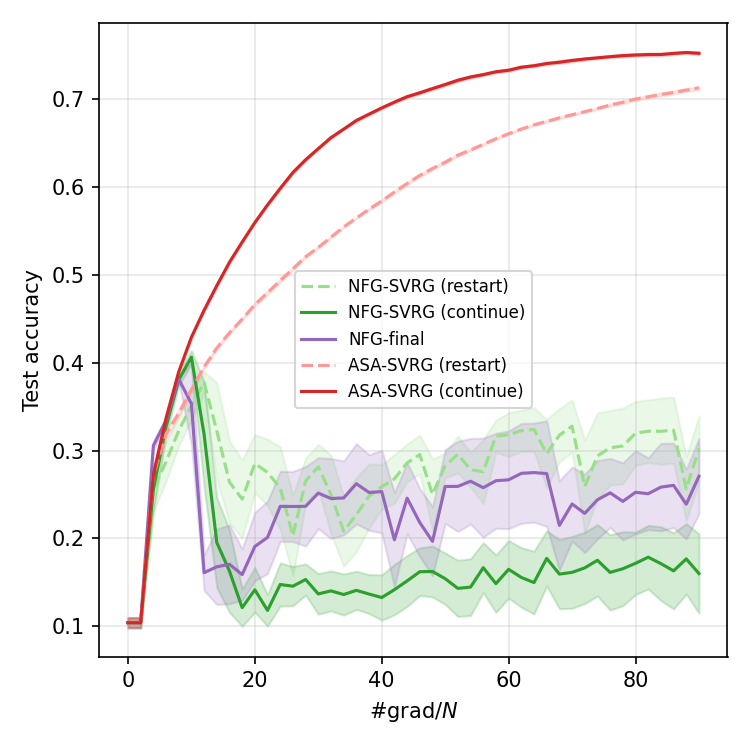

e2_average_gradient_train_loss.png


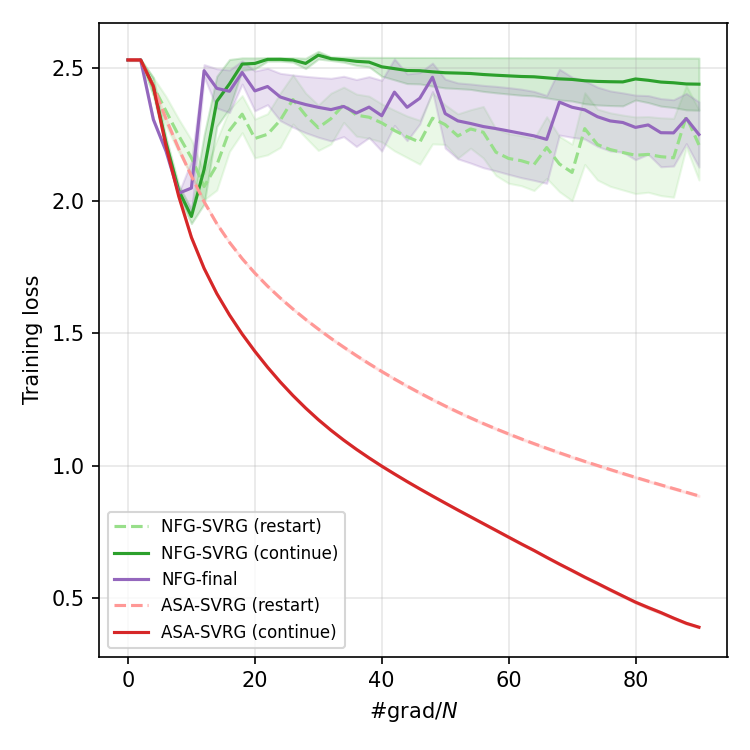

e2_omega.png


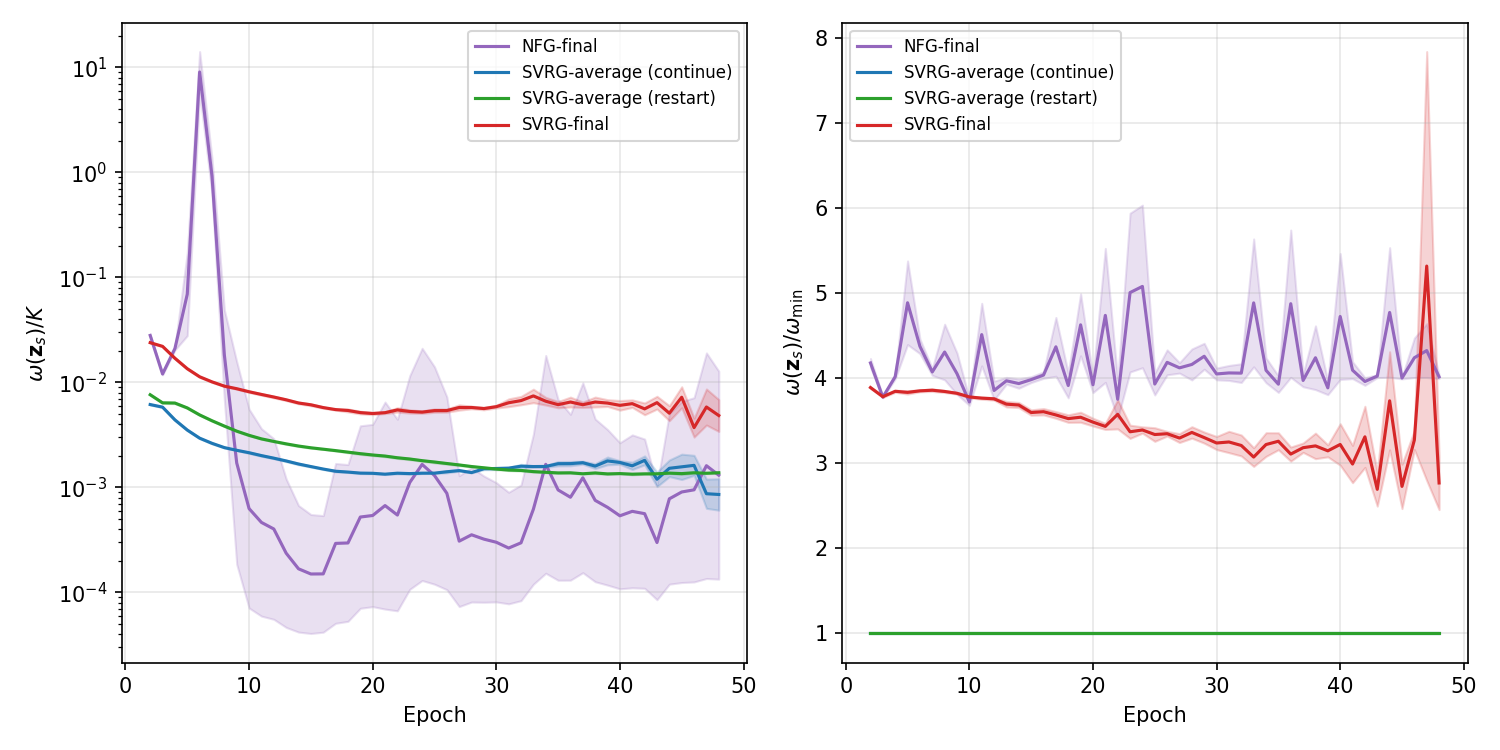

In [3]:
import glob
for path in sorted(glob.glob(os.path.join(a2.FIGURE_DIR, '*.png'))):
    print(os.path.basename(path))
    display(Image(filename=path, width=420))